# 18 - Market Basket Analysis: which rules are real?
**Topic:** Recommendation Systems  |  **Reference:** "Market Basket Analysis using Python" (amanxai.com, Oct 2023)

**Question.** Which products are bought together, and can that be used to suggest an extra item for a basket?

**Reference method:** a small basket file, Apriori to find frequent itemsets, association rules ranked by support / confidence / lift, and a reading of the top rules as business insights.
**What I add:** (1) the reference's own file (250 baskets) and a **real grocery data set (9,835 baskets, 171 items)**, so I can show what changes with data size; (2) a **null test**: are the rules any stronger than rules found in baskets with the same item popularity but random contents? (3) **hold-out validation**: do rules found in one part of the data keep their lift in another part? (4) a **basket-completion test**: hide one item from a held-out basket and see whether the rules put it in the top 5, against a popularity baseline.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, time, ast
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import sparse
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(0); os.makedirs("model", exist_ok=True)
gro = [l.strip().split(",") for l in open("../_data/groceries.csv", encoding="utf8") if l.strip()]
ref = [ast.literal_eval(t) for t in pd.read_csv("../_data/basket/market_basket_dataset.csv")["Transaction"]]
def onehot(baskets, vocab=None):
    vocab = vocab or sorted({i for b in baskets for i in b}); ix = {v: k for k, v in enumerate(vocab)}
    rows = [r for r, b in enumerate(baskets) for i in set(b) if i in ix]; cols = [ix[i] for b in baskets for i in set(b) if i in ix]
    return sparse.csr_matrix((np.ones(len(rows), bool), (rows, cols)), shape=(len(baskets), len(vocab))), vocab
G, gv = onehot(gro); R, rv = onehot(ref)
print("groceries:", G.shape, "| the reference's file:", R.shape)

groceries: (9835, 171) | the reference's file: (250, 7)


## 2. Look at the data first

groceries: basket size mean 4.4, median 3, max 32 | density of the basket x item grid: 2.6% | baskets with 1 item: 22.0%
reference file: 250 baskets, 7 items, basket size mean 3.1 (min 1, max 5) | items: ['Bread', 'Butter', 'Chips', 'Cold Drink', 'Fruit Cake', 'Juice', 'Milk']


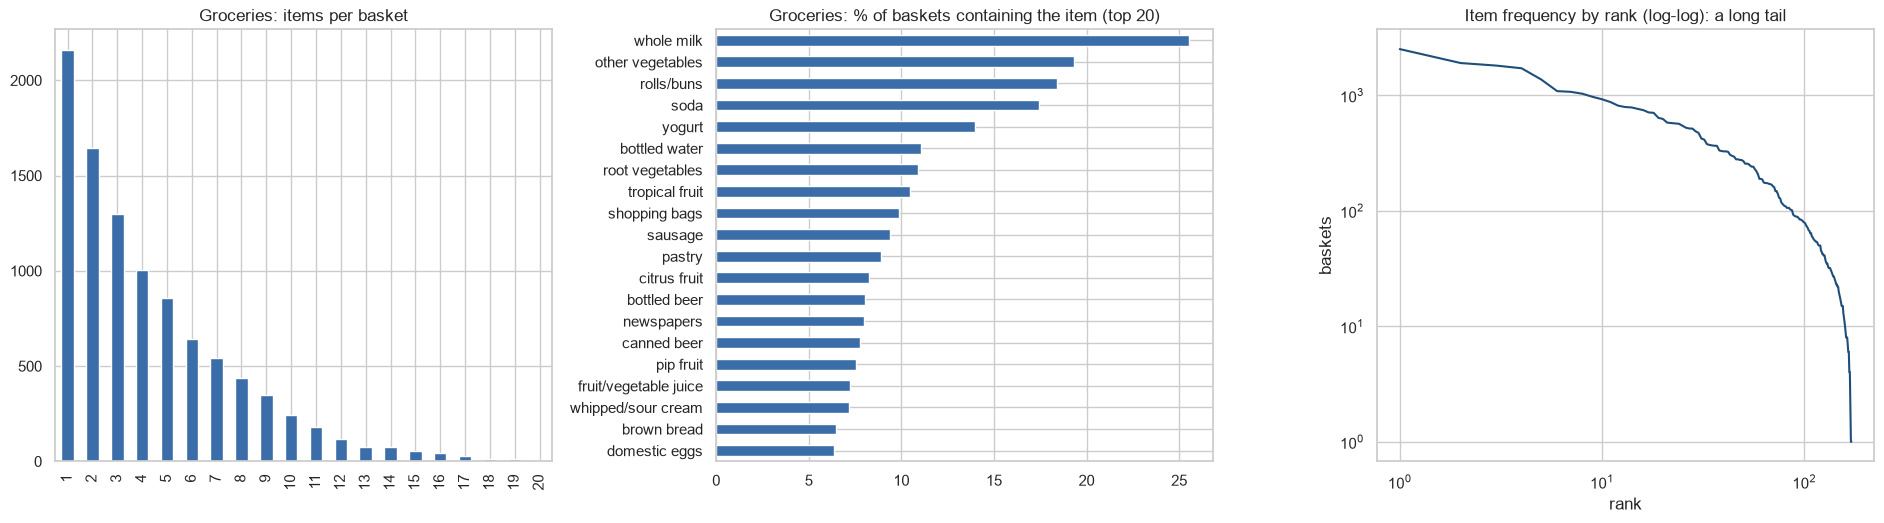

In [2]:
gs = np.asarray(G.sum(1)).ravel(); rsz = np.asarray(R.sum(1)).ravel(); gf = pd.Series(np.asarray(G.sum(0)).ravel() / len(gro), index=gv).sort_values(ascending=False)
print("groceries: basket size mean %.1f, median %d, max %d | density of the basket x item grid: %.1f%% | baskets with 1 item: %.1f%%" % (gs.mean(), np.median(gs), gs.max(), G.mean() * 100, (gs == 1).mean() * 100))
print("reference file: %d baskets, %d items, basket size mean %.1f (min %d, max %d)" % (R.shape[0], R.shape[1], rsz.mean(), rsz.min(), rsz.max()), "| items:", rv)
fig, ax = plt.subplots(1, 3, figsize=(19, 5.4))
pd.Series(gs).value_counts().sort_index().head(20).plot.bar(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Groceries: items per basket"); ax[0].set_xlabel("")
(gf.head(20).iloc[::-1] * 100).plot.barh(ax=ax[1], color="#3b6ea8"); ax[1].set_title("Groceries: % of baskets containing the item (top 20)")
ax[2].loglog(np.arange(1, len(gf) + 1), gf.values * len(gro), color="#1f4e79"); ax[2].set_title("Item frequency by rank (log-log): a long tail"); ax[2].set_xlabel("rank"); ax[2].set_ylabel("baskets")
plt.tight_layout(); plt.show()

**Reading it.** The groceries file has 9,835 baskets and 171 items; the typical basket is small (mean 4.4 items, median 3; 22% of baskets have a single item; the largest has 32). Only 2.6% of the basket-by-item grid is filled. Item frequency has a long tail: a handful of staples appear in a large share of baskets (the next cell's rules show whole milk constantly) while 84 of the 171 items appear in under 1% of baskets, so any rule about rare items rests on few baskets. The reference's file is very different: 250 baskets over only **7 items** (bread, butter, chips, cold drink, fruit cake, juice, milk), 1-5 items per basket (mean 3.1).

## 3. Frequent itemsets and rules: Apriori vs FP-growth
Both find the same itemsets; FP-growth is built to be faster. Minimum support 0.5% (about 49 baskets of 9,835). A rule `A -> B` has **support** P(A and B), **confidence** P(B | A) and **lift** = confidence / P(B): lift 1 means A tells you nothing about B.

In [3]:
D = pd.DataFrame.sparse.from_spmatrix(G, columns=gv).astype(bool)
t = time.time(); f_ap = apriori(D, min_support=0.005, use_colnames=True); t_ap = time.time() - t
t = time.time(); f_fp = fpgrowth(D, min_support=0.005, use_colnames=True); t_fp = time.time() - t
print("itemsets (support >= 0.5%%): Apriori %d in %.1fs | FP-growth %d in %.1fs | identical: %s" % (len(f_ap), t_ap, len(f_fp), t_fp, set(map(frozenset, f_ap.itemsets)) == set(map(frozenset, f_fp.itemsets))))
rules = association_rules(f_fp, metric="confidence", min_threshold=0.1)
rules["n_a"] = rules.antecedents.map(len); rules["n_c"] = rules.consequents.map(len)
print("rules with confidence >= 10%%: %d | by antecedent size: %s" % (len(rules), rules.n_a.value_counts().sort_index().to_dict()))
show = lambda d: d.assign(rule=d.antecedents.map(lambda s: " + ".join(sorted(s))) + "  ->  " + d.consequents.map(lambda s: " + ".join(sorted(s))))[["rule", "support", "confidence", "lift"]].round(3).to_string(index=False)
print("\nTOP 8 BY CONFIDENCE:"); print(show(rules.sort_values("confidence", ascending=False).head(8)))
print("\nTOP 8 BY LIFT:"); print(show(rules.sort_values("lift", ascending=False).head(8)))

itemsets (support >= 0.5%): Apriori 1000 in 0.3s | FP-growth 1000 in 0.3s | identical: True
rules with confidence >= 10%: 1751 | by antecedent size: {1: 872, 2: 831, 3: 48}

TOP 8 BY CONFIDENCE:
                                                             rule  support  confidence  lift
        root vegetables + tropical fruit + yogurt  ->  whole milk    0.006       0.700 2.740
   other vegetables + pip fruit + root vegetables  ->  whole milk    0.005       0.675 2.642
                      butter + whipped/sour cream  ->  whole milk    0.007       0.660 2.583
                   pip fruit + whipped/sour cream  ->  whole milk    0.006       0.648 2.537
                                  butter + yogurt  ->  whole milk    0.009       0.639 2.500
                         butter + root vegetables  ->  whole milk    0.008       0.638 2.496
                            curd + tropical fruit  ->  whole milk    0.007       0.634 2.480
citrus fruit + root vegetables + whole milk  ->  other vegeta

**Reading it.**
* Apriori and FP-growth return the identical 1,000 itemsets (support >= 0.5%) and take the same time (0.3 s) at this size; FP-growth's speed advantage matters for much larger data.
* Of 1,751 rules with confidence >= 10%, 872 have one item on the left, 831 have two and 48 have three.
* **Ranking by confidence puts whole milk on the right of almost every rule** (confidence 63-70% with lift 2.5-2.7 for rules such as root vegetables + tropical fruit + yogurt -> whole milk), because whole milk is in about a quarter of all baskets: a frequent item is easy to "predict". Lift removes that effect: the rules with the **highest lift (4.6-5.2)** are about specific combinations, for example (tropical fruit + whole milk) <-> (root vegetables + yogurt), and ham <-> white bread (lift 4.6; confidence 12-20% because both are rare).
* A high-lift rule says the items occur together far more than independence predicts, not that most buyers of A also buy B (ham -> white bread has confidence 19.5%).

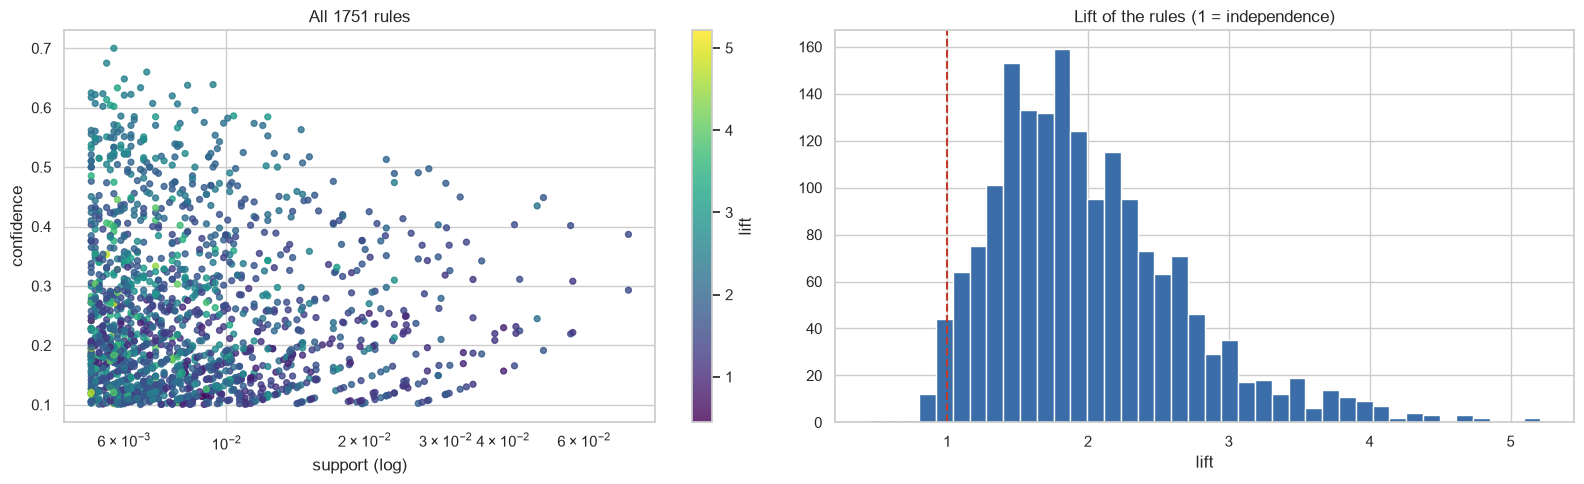

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sc = ax[0].scatter(rules.support, rules.confidence, c=rules.lift, cmap="viridis", s=18, alpha=.8); plt.colorbar(sc, ax=ax[0], label="lift"); ax[0].set_xscale("log"); ax[0].set_xlabel("support (log)"); ax[0].set_ylabel("confidence"); ax[0].set_title("All %d rules" % len(rules))
ax[1].hist(rules.lift, bins=40, color="#3b6ea8"); ax[1].axvline(1, color="#c0392b", ls="--"); ax[1].set_title("Lift of the rules (1 = independence)"); ax[1].set_xlabel("lift")
plt.tight_layout(); plt.show()

## 4. Null test: are these lifts bigger than chance would give?
**Null data:** keep every basket's size and every item's overall frequency, but fill baskets at random (each item column is shuffled independently across baskets, so the items become independent of each other). Mine rules with the same settings and compare the lift distribution and the number of rules above lift thresholds. A real association should be far outside what the null produces.

In [5]:
def null_rules(seed):
    r = np.random.RandomState(seed); M = G.toarray()
    for j in range(M.shape[1]): M[:, j] = r.permutation(M[:, j])
    d = pd.DataFrame(M.astype(bool), columns=gv); f = fpgrowth(d, min_support=0.005, use_colnames=True)
    return association_rules(f, metric="confidence", min_threshold=0.1) if len(f) > 1 else pd.DataFrame({"lift": [], "confidence": []})
nulls = [null_rules(s) for s in range(5)]
rows = []
for th in (1.2, 1.5, 2.0, 2.5, 3.0):
    rows.append([th, (rules.lift >= th).sum(), np.mean([(n.lift >= th).sum() for n in nulls])])
N = pd.DataFrame(rows, columns=["lift >=", "rules in the real data", "rules in shuffled data (mean of 5)"]); print(N.to_string(index=False))
print("\nmax lift: real %.2f | shuffled: %s" % (rules.lift.max(), [round(n.lift.max(), 2) if len(n) else None for n in nulls]))

 lift >=  rules in the real data  rules in shuffled data (mean of 5)
     1.2                    1599                                22.2
     1.5                    1325                                 0.4
     2.0                     748                                 0.0
     2.5                     356                                 0.0
     3.0                     152                                 0.0

max lift: real 5.21 | shuffled: [np.float64(1.32), np.float64(1.6), np.float64(1.52), np.float64(1.35), np.float64(1.39)]


**Reading it.** In baskets with the same item frequencies but random contents, only about 22 rules reach lift 1.2 and **almost none (0.4 on average) reach 1.5, none reach 2**; the largest lift in any shuffled copy is 1.3-1.6. The real data have 1,325 rules at lift >= 1.5, 748 at >= 2 and 152 at >= 3, and a maximum of 5.2. So for the grocery data **the strong rules are far outside what chance produces**; these are real co-purchase patterns (for example, produce and dairy bought in one trip).

## 5. Do rules survive on new baskets? (hold-out validation)
Mine rules on a random 60% of the baskets, then recompute each rule's lift on the other 40%. Rules chosen *because* their lift was the highest are partly lucky, so we expect their lift to fall: how much?

                rules  mean_lift_train  mean_lift_test  mean_conf_train  mean_conf_test
bucket                                                                                 
(0.419, 1.463]    363            1.233           1.241            0.190           0.188
(1.463, 1.78]     363            1.632           1.585            0.239           0.234
(1.78, 2.112]     362            1.933           1.877            0.254           0.248
(2.112, 2.575]    363            2.332           2.165            0.293           0.273
(2.575, 8.807]    363            3.186           2.865            0.258           0.234

the 15 rules with the highest TRAIN lift: mean lift train 5.57 -> test 4.88 | share with test lift > 1: 100%
correlation of train lift and test lift over all 1814 rules (Spearman): 0.82


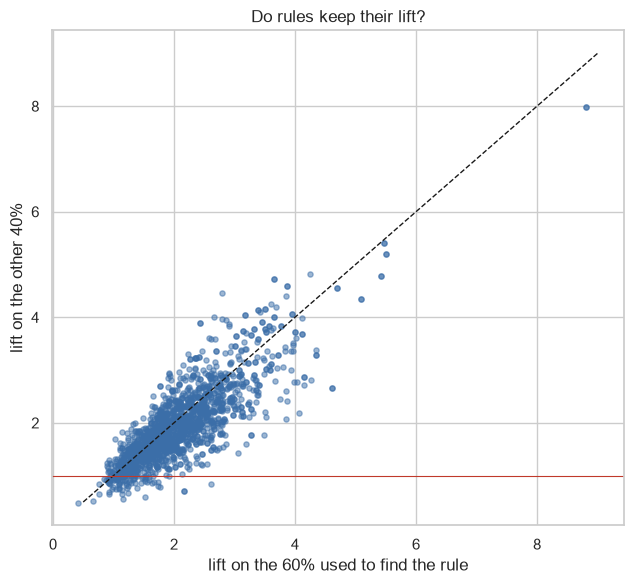

In [6]:
rs = np.random.RandomState(0); perm = rs.permutation(len(gro)); a_i, b_i = perm[:int(.6 * len(perm))], perm[int(.6 * len(perm)):]
Da = pd.DataFrame.sparse.from_spmatrix(G[a_i], columns=gv).astype(bool); fa = fpgrowth(Da, min_support=0.005, use_colnames=True); ra = association_rules(fa, metric="confidence", min_threshold=0.1)
Gb = G[b_i].toarray().astype(bool); ix = {v: k for k, v in enumerate(gv)}
def lift_on(Gx, ant, con):
    a = Gx[:, [ix[i] for i in ant]].all(1); c = Gx[:, [ix[i] for i in con]].all(1)
    return (a & c).mean() / (a.mean() * c.mean() + 1e-12) if a.sum() >= 5 and c.sum() >= 5 else np.nan, int(a.sum()), (a & c).mean() / (a.mean() + 1e-12) if a.sum() else np.nan
ev = [lift_on(Gb, set(r.antecedents), set(r.consequents)) for r in ra.itertuples()]
ra["lift_test"], ra["n_ant_test"], ra["conf_test"] = [e[0] for e in ev], [e[1] for e in ev], [e[2] for e in ev]
q = ra.dropna(subset=["lift_test"]); q = q[q.n_ant_test >= 20]
q["bucket"] = pd.qcut(q.lift, 5, duplicates="drop")
S = q.groupby("bucket", observed=True).agg(rules=("lift", "size"), mean_lift_train=("lift", "mean"), mean_lift_test=("lift_test", "mean"), mean_conf_train=("confidence", "mean"), mean_conf_test=("conf_test", "mean")); print(S.round(3).to_string())
top = q.sort_values("lift", ascending=False).head(15); print("\nthe 15 rules with the highest TRAIN lift: mean lift train %.2f -> test %.2f | share with test lift > 1: %.0f%%" % (top.lift.mean(), top.lift_test.mean(), (top.lift_test > 1).mean() * 100))
print("correlation of train lift and test lift over all %d rules (Spearman): %.2f" % (len(q), q[["lift", "lift_test"]].corr(method="spearman").iloc[0, 1]))
fig, ax = plt.subplots(figsize=(6.5, 6)); ax.scatter(q.lift, q.lift_test, s=14, alpha=.5, color="#3b6ea8"); lim = [0.5, max(q.lift.max(), q.lift_test.max()) + .2]; ax.plot(lim, lim, "k--", lw=1); ax.axhline(1, color="#c0392b", lw=.8); ax.set_xlabel("lift on the 60% used to find the rule"); ax.set_ylabel("lift on the other 40%"); ax.set_title("Do rules keep their lift?"); plt.tight_layout(); plt.show()

**Reading it.** Rules mined on 60% of the baskets keep their lift on the unseen 40%: the 15 highest-lift rules go from a mean lift of 5.57 to 4.88 (a loss of about 12%, the expected shrinkage when you pick the best of many) and **all 15 stay above 1**; across all 1,814 rules the rank correlation between training and test lift is 0.82. Confidence behaves the same way (for example 0.258 to 0.234 in the top bucket). Rules are therefore stable at this data size; rules with antecedents seen in fewer than 20 held-out baskets were excluded from this table, so very rare rules are not covered.

## 6. A use test: complete a basket
For every held-out basket with 2+ items, **hide one random item** and ask each method for 5 suggestions given the rest. A **hit** is when the hidden item is among them. Methods: **popularity** (the 5 most frequent items not already in the basket); **single-item rules** (for each basket item i and candidate j, use confidence P(j|i); take the max); **lift-weighted** (sum of lift-weighted confidences, requiring at least 20 co-occurrences); **multi-item rules from Apriori** (the reference's way: rules with confidence >= 10%, best matching rule).

In [7]:
Ga = G[a_i].tocsr().astype(np.float32); cnt = np.asarray(Ga.sum(0)).ravel(); co = (Ga.T @ Ga).toarray(); np.fill_diagonal(co, 0)
conf = co / np.maximum(cnt[:, None], 1); pj = cnt / Ga.shape[0]; liftm = conf / np.maximum(pj[None, :], 1e-9); liftm[co < 20] = 0
rule_list = [(set(r.antecedents), set(r.consequents), r.confidence) for r in ra.itertuples()]
def recommend(basket_idx, method, k=5):
    s = np.zeros(len(gv))
    if method == "popularity": s = cnt.copy()
    elif method == "single-item rules (max confidence)": s = conf[basket_idx].max(0)
    elif method == "lift-weighted (>= 20 co-occurrences)": s = (conf[basket_idx] * liftm[basket_idx]).sum(0)
    elif method == "Apriori rules (multi-item antecedents)":
        names = {gv[i] for i in basket_idx}
        for a, c, cf in rule_list:
            if a <= names:
                for it_ in c: s[ix[it_]] = max(s[ix[it_]], cf)
        s = s + 1e-6 * cnt                                  # ties and uncovered baskets fall back to popularity
    s[basket_idx] = -1; return np.argsort(-s)[:k]
rng = np.random.RandomState(1); cases = []
for r in b_i:
    items = G[r].indices
    if len(items) >= 2: h = rng.choice(items); cases.append(([i for i in items if i != h], h))
methods = ["popularity", "single-item rules (max confidence)", "lift-weighted (>= 20 co-occurrences)", "Apriori rules (multi-item antecedents)"]
hits = {m: np.array([h in recommend(np.array(rest), m) for rest, h in cases], float) for m in methods}
rngb = np.random.RandomState(2); Bs = rngb.randint(0, len(cases), (1000, len(cases)))
HR = pd.DataFrame({m: {"hit_rate@5_%": v.mean() * 100, "ci_low": np.percentile(v[Bs].mean(1), 2.5) * 100, "ci_high": np.percentile(v[Bs].mean(1), 97.5) * 100} for m, v in hits.items()}).T
print(len(cases), "held-out baskets with 2+ items"); print(HR.round(1).to_string())
d = (hits[methods[2]] - hits[methods[0]])[Bs].mean(1) * 100; print("\nlift-weighted minus popularity: %.1f points (95%% interval %.1f to %.1f)" % ((hits[methods[2]] - hits[methods[0]]).mean() * 100, *np.percentile(d, [2.5, 97.5])))

3074 held-out baskets with 2+ items
                                        hit_rate@5_%  ci_low  ci_high
popularity                                      25.8    24.3     27.3
single-item rules (max confidence)              26.4    24.9     28.0
lift-weighted (>= 20 co-occurrences)            26.0    24.5     27.6
Apriori rules (multi-item antecedents)          27.3    25.7     28.7

lift-weighted minus popularity: 0.2 points (95% interval -1.0 to 1.5)


**Reading it (3,074 held-out baskets with 2+ items; one random item hidden; 5 suggestions).**
* Recommending the five most popular items not already in the basket finds the hidden item **25.8%** of the time (95% interval 24.3-27.3). Single-item rules reach 26.4%, the lift-weighted version 26.0% and the Apriori multi-item rules 27.3%.
* **The differences are inside the noise:** for lift-weighted minus popularity the paired interval is -1.0 to +1.5 points; I did not compute paired intervals for the others, but the intervals of all four overlap heavily.
* So the rules are *real* (previous sections) but **do not help predict the next item** beyond "what is popular", because the hidden item is usually one of the staples that everybody buys. Rules are better for what they were designed for, understanding which *combinations* occur (store layout, bundles), than for beating a popularity list at completing a random basket. The test is a hard one (hiding a random item, which is often a staple), and a different task (suggesting an item for the most specific part of the basket) could look different.

## 7. The reference's own file (250 baskets): how stable are its rules?
Same procedure, scaled to the data: minimum support 5%. Rules mined on two random halves of the 250 baskets, and a bootstrap confidence interval for the lift of the top rules.

In [8]:
Dr = pd.DataFrame.sparse.from_spmatrix(R, columns=rv).astype(bool)
fr = fpgrowth(Dr, min_support=0.05, use_colnames=True); rr = association_rules(fr, metric="lift", min_threshold=1.0); rr = rr[(rr.antecedents.map(len) == 1) & (rr.consequents.map(len) == 1)]
rr["rule"] = rr.antecedents.map(lambda s: list(s)[0]) + " -> " + rr.consequents.map(lambda s: list(s)[0]); top = rr.sort_values("lift", ascending=False).head(6)
Rm = R.toarray().astype(bool); rix = {v: k for k, v in enumerate(rv)}; rb = np.random.RandomState(0); rows = []
for t_ in top.itertuples():
    a, c = rix[list(t_.antecedents)[0]], rix[list(t_.consequents)[0]]; ls = []
    for _ in range(1000):
        s = rb.randint(0, len(Rm), len(Rm)); x = Rm[s]; pa, pc = x[:, a].mean(), x[:, c].mean(); ls.append((x[:, a] & x[:, c]).mean() / (pa * pc) if pa * pc > 0 else np.nan)
    rows.append([t_.rule, t_.support, t_.confidence, t_.lift, np.nanpercentile(ls, 2.5), np.nanpercentile(ls, 97.5)])
BT = pd.DataFrame(rows, columns=["rule", "support", "confidence", "lift", "lift_ci_low", "lift_ci_high"]); print(BT.round(2).to_string(index=False))
def rule_set(idx):
    f = fpgrowth(pd.DataFrame.sparse.from_spmatrix(R[idx], columns=rv).astype(bool), min_support=0.05, use_colnames=True); rl = association_rules(f, metric="lift", min_threshold=1.0)
    rl = rl[(rl.antecedents.map(len) == 1) & (rl.consequents.map(len) == 1)]; return rl.assign(rule=rl.antecedents.map(lambda s: list(s)[0]) + " -> " + rl.consequents.map(lambda s: list(s)[0])).sort_values("lift", ascending=False)
ov = []
for s in range(10):
    p_ = np.random.RandomState(s).permutation(250); A, B = rule_set(p_[:125]), rule_set(p_[125:]); ov.append(len(set(A.rule.head(5)) & set(B.rule.head(5))))
print("\nTop-5 rules by lift found on two random halves: overlap of the two lists over 10 random splits: mean %.1f of 5 (range %d-%d)" % (np.mean(ov), min(ov), max(ov)))

               rule  support  confidence  lift  lift_ci_low  lift_ci_high
     Bread -> Juice     0.21        0.51  1.16         0.99          1.33
     Juice -> Bread     0.21        0.47  1.16         1.00          1.34
Bread -> Fruit Cake     0.20        0.49  1.14         0.97          1.34
Fruit Cake -> Bread     0.20        0.46  1.14         0.97          1.33
Cold Drink -> Juice     0.22        0.49  1.11         0.94          1.27
Juice -> Cold Drink     0.22        0.49  1.11         0.95          1.25



Top-5 rules by lift found on two random halves: overlap of the two lists over 10 random splits: mean 0.1 of 5 (range 0-1)


**Reading it.** In the reference's 250-basket file, the strongest single-item rules have **lift 1.11-1.16, with 95% bootstrap intervals that include 1** (for example Bread -> Juice: lift 1.16, interval 0.99-1.33). The top-5 rules found on two random halves of the 250 baskets overlap by only **0.1 of 5 rules on average** (0-1 across 10 random splits): rules from one half say nothing about the other. This file shows no reliable association structure; a "business insight" drawn from its top rules would be a story about noise. (As in notebook 08, the flat counts and independence suggest the file was generated at random, though the source does not say.)

## 8. Save the rule tables and co-occurrence data for the app

In [9]:
final_rules = rules.assign(antecedents=rules.antecedents.map(lambda s: "|".join(sorted(s))), consequents=rules.consequents.map(lambda s: "|".join(sorted(s)))).sort_values("lift", ascending=False)
final_rules[["antecedents", "consequents", "support", "confidence", "lift", "n_a", "n_c"]].round(5).to_csv("model/groceries_rules.csv", index=False)
Gall = G.astype(np.float32); cnt_all = np.asarray(Gall.sum(0)).ravel(); co_all = (Gall.T @ Gall).toarray(); np.fill_diagonal(co_all, 0)
joblib.dump({"items": gv, "counts": cnt_all, "cooc": co_all.astype(np.float32), "n_baskets": G.shape[0], "min_cooc": 20}, "model/basket_cooccurrence.joblib")
json.dump({"hit_rate": HR.round(2).to_dict("index"), "null": N.to_dict("records"), "n_rules": int(len(rules)), "holdout_buckets": S.reset_index(drop=True).round(3).to_dict("records")}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['basket_cooccurrence.joblib', 'groceries_rules.csv', 'meta.json']


## 9. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | 250-basket toy file (7 items) | the same file, plus real groceries: 9,835 baskets, 171 items |
| Method | Apriori and rules by support / confidence / lift | + FP-growth check, null test by shuffling, hold-out validation, basket-completion test |
| Is it real? | not tested | **groceries: yes** (1,325 rules with lift >= 1.5 vs 0.4 in shuffled data; top rules keep 88% of their lift on new baskets). **Reference file: no** (lifts 1.11-1.16, intervals include 1, two halves share 0.1 of the top 5 rules) |
| Is it useful? | "business insights" | rules complete a basket no better than popularity (26-27% vs 25.8% hit rate@5) |

**What I learned.** (1) Rank by lift, not confidence: confidence just rediscovers popular items. (2) Test rules against shuffled data and on held-out baskets before believing them. (3) A statistically real pattern need not be a useful prediction: say what the rule is *for*. (4) Small baskets with few items can give impressive-looking but empty rules.

**Limits.** The groceries file has no dates or customers, so the validation split is random; support threshold 0.5% hides rarer rules; the completion test hides one random item (one of several possible tasks); confidence intervals are over baskets. **Next step:** price and margin data to rank rules by profit, and a sequence-aware (next basket) model with timestamps.